In [3]:
import os

for root, dirs, files in os.walk('/'):
    if 'group_sample_seed43.csv' in files:
        print("File location:", os.path.join(root, 'group_sample_seed43.csv'))
        break

File location: /group_sample_seed43.csv


In [4]:
import pandas as pd
import numpy as np

# Load the original M1 dataset
df = pd.read_csv('/group_sample_seed43.csv')

# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check columns
print("\nColumn names:")
print(df.columns.tolist())

# Display first 5 rows
display(df.head())

Dataset shape: (50000, 10)

Column names:
['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text']


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,506993,B000HBMHVM,A1809JJDV0J0K4,nez,5,6,3,1162944000,Decent cup,"Decent flavor, slightly bitter aftertaste. Not..."
1,96498,B002J42VPW,AJJX7EZHZ5LLB,"Sean J. Brown ""Occassional Buyer""",0,0,4,1289520000,Flint River ranch lamb and rice,I have a Westie with allergies and this produc...
2,384410,B0001UQWEC,A1R0NOLDRD274T,"Bryan M. Griffith ""A business litigation atto...",1,8,1,1170028800,I must be a nut to have bought these nuts,The bottle arrived half empty. I am not saying...
3,547667,B006HYLW32,A2ZEFDVX4X5TPX,"Thomas A. Roberts ""tomrgalvtx""",0,0,4,1284163200,always something new and different,"If you like potato chips, then, you must try t..."
4,225850,B0035RLCLQ,A1MU4SGS7R0PNR,S. Fernandez,1,1,5,1310947200,Forget the other sea salt I've been using!,Received the pink pure Himalayan salt and was ...


In [5]:
# Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# Check duplicate review texts
print("\nNumber of duplicate review texts:")
print(df['Text'].duplicated().sum())

Missing values in each column:
Id                        0
ProductId                 0
UserId                    0
ProfileName               1
HelpfulnessNumerator      0
HelpfulnessDenominator    0
Score                     0
Time                      0
Summary                   4
Text                      0
dtype: int64

Number of duplicate rows:
0

Number of duplicate review texts:
3736


In [6]:
# Create sentiment labels based on star ratings

def assign_sentiment(score):
    if score <= 2:
        return "Negative"
    elif score == 3:
        return "Neutral"
    else:
        return "Positive"

df['Sentiment'] = df['Score'].apply(assign_sentiment)

# Check the results
print(df[['Score', 'Sentiment']].head(10))

   Score Sentiment
0      3   Neutral
1      4  Positive
2      1  Negative
3      4  Positive
4      5  Positive
5      5  Positive
6      5  Positive
7      3   Neutral
8      2  Negative
9      5  Positive


In [7]:
# Count the number of reviews in each sentiment class

print(df['Sentiment'].value_counts())

# Calculate percentages
print("\nClass distribution (%):")
print(df['Sentiment'].value_counts(normalize=True) * 100)

Sentiment
Positive    39012
Negative     7227
Neutral      3761
Name: count, dtype: int64

Class distribution (%):
Sentiment
Positive    78.024
Negative    14.454
Neutral      7.522
Name: proportion, dtype: float64


In [8]:
from sklearn.model_selection import train_test_split

# Input: review text
X = df['Text']

# Target: sentiment labels
y = df['Sentiment']

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check the sizes
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

# Check class distribution
print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training set: (40000,)
Testing set: (10000,)

Training class distribution:
Sentiment
Positive    78.0250
Negative    14.4525
Neutral      7.5225
Name: proportion, dtype: float64

Testing class distribution:
Sentiment
Positive    78.02
Negative    14.46
Neutral      7.52
Name: proportion, dtype: float64


In [10]:
import re
import html

def clean_text(text):
    # Decode HTML entities
    text = html.unescape(text)

    # Remove HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)

    # Convert to lowercase
    text = text.lower()

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [11]:
# Apply text preprocessing
X_train_clean = X_train.apply(clean_text)
X_test_clean = X_test.apply(clean_text)

# Compare original and cleaned reviews
print("Original review:")
print(X_train.iloc[0])

print("\nCleaned review:")
print(X_train_clean.iloc[0])

Original review:
I was looking for something that would work well for a meal replacement that I didn't have to choke down. Well this actually tastes quite good. I was very surprised after trying a different protein. The Vanilla is Peruvian vanilla so it doesn't hit you over the head with vanilla like some powders do. Like another reviewer said it is very thick- you probably don't want to make it too much before you drink it because the longer you let it sit the more thick it seems to become. I tried mixing w/out a blender and I had many many clumps in my glass.

Cleaned review:
i was looking for something that would work well for a meal replacement that i didn't have to choke down. well this actually tastes quite good. i was very surprised after trying a different protein. the vanilla is peruvian vanilla so it doesn't hit you over the head with vanilla like some powders do. like another reviewer said it is very thick- you probably don't want to make it too much before you drink it beca

In [12]:
print("Training samples:", len(X_train_clean))
print("Testing samples:", len(X_test_clean))

print("\nMissing values in training:",
      X_train_clean.isnull().sum())

print("Missing values in testing:",
      X_test_clean.isnull().sum())

Training samples: 40000
Testing samples: 10000

Missing values in training: 0
Missing values in testing: 0


In [13]:
from sklearn.feature_extraction.text import CountVectorizer

# Initialize Bag of Words vectorizer
bow_vectorizer = CountVectorizer(
    max_features=20000,
    min_df=2
)

# Fit on training data and transform
X_train_bow = bow_vectorizer.fit_transform(X_train_clean)

# Transform testing data
X_test_bow = bow_vectorizer.transform(X_test_clean)

# Check results
print("Training matrix shape:", X_train_bow.shape)
print("Testing matrix shape:", X_test_bow.shape)

print("Vocabulary size:", len(bow_vectorizer.vocabulary_))

Training matrix shape: (40000, 20000)
Testing matrix shape: (10000, 20000)
Vocabulary size: 20000


In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
    max_features=20000,
    min_df=2
)

# Fit on training data and transform
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_clean)

# Transform testing data
X_test_tfidf = tfidf_vectorizer.transform(X_test_clean)

# Check results
print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

print("Vocabulary size:", len(tfidf_vectorizer.vocabulary_))

Training matrix shape: (40000, 20000)
Testing matrix shape: (10000, 20000)
Vocabulary size: 20000


In [15]:
print("BoW:")
print("Training:", X_train_bow.shape)
print("Testing:", X_test_bow.shape)

print("\nTF-IDF:")
print("Training:", X_train_tfidf.shape)
print("Testing:", X_test_tfidf.shape)

BoW:
Training: (40000, 20000)
Testing: (10000, 20000)

TF-IDF:
Training: (40000, 20000)
Testing: (10000, 20000)


In [16]:
from sklearn.feature_selection import chi2
import numpy as np

def get_top_features(X, y, vectorizer, class_name, top_n=10):
    # Convert target into binary: target class vs all other classes
    y_binary = (y == class_name).astype(int)

    # Calculate Chi-square scores
    scores, p_values = chi2(X, y_binary)

    # Get vocabulary words
    feature_names = vectorizer.get_feature_names_out()

    # Select top features
    top_indices = np.argsort(scores)[::-1][:top_n]

    return [
        (feature_names[i], scores[i])
        for i in top_indices
    ]


# Analyze BoW features
for sentiment in ['Positive', 'Negative']:
    print(f"\nTop 10 BoW Features for {sentiment}:")
    results = get_top_features(
        X_train_bow,
        y_train,
        bow_vectorizer,
        sentiment
    )

    for word, score in results:
        print(f"{word}: {score:.2f}")


# Analyze TF-IDF features
for sentiment in ['Positive', 'Negative']:
    print(f"\nTop 10 TF-IDF Features for {sentiment}:")
    results = get_top_features(
        X_train_tfidf,
        y_train,
        tfidf_vectorizer,
        sentiment
    )

    for word, score in results:
        print(f"{word}: {score:.2f}")


Top 10 BoW Features for Positive:
not: 2742.32
was: 2562.13
the: 2384.06
but: 1169.34
great: 985.22
bad: 924.69
disappointed: 792.44
would: 786.91
thought: 768.53
were: 706.02

Top 10 BoW Features for Negative:
was: 1997.50
not: 1442.26
the: 893.64
great: 798.63
disappointed: 778.95
worst: 761.43
money: 760.15
return: 730.66
awful: 686.06
horrible: 598.72

Top 10 TF-IDF Features for Positive:
not: 136.58
great: 101.52
worst: 101.09
disappointed: 97.61
bad: 92.52
awful: 85.88
was: 84.67
return: 84.64
ok: 79.89
horrible: 77.89

Top 10 TF-IDF Features for Negative:
worst: 145.54
awful: 128.33
return: 115.84
horrible: 111.82
disappointed: 106.60
threw: 105.90
terrible: 102.60
waste: 100.23
money: 82.13
not: 80.51


In [17]:
print("BoW Vocabulary Size:",
      len(bow_vectorizer.vocabulary_))

print("TF-IDF Vocabulary Size:",
      len(tfidf_vectorizer.vocabulary_))

BoW Vocabulary Size: 20000
TF-IDF Vocabulary Size: 20000


In [18]:
def get_directional_features(X, y, vectorizer,
                              class_name, top_n=10):

    y_binary = (y == class_name).to_numpy()

    # Calculate Chi-square scores
    scores, _ = chi2(X, y_binary)

    # Calculate average feature values
    class_mean = np.asarray(
        X[y_binary].mean(axis=0)
    ).ravel()

    other_mean = np.asarray(
        X[~y_binary].mean(axis=0)
    ).ravel()

    # Keep features more prevalent in the target class
    mask = class_mean > other_mean

    # Select top features
    indices = np.where(mask)[0]
    top_indices = indices[
        np.argsort(scores[indices])[::-1][:top_n]
    ]

    feature_names = vectorizer.get_feature_names_out()

    return [
        (feature_names[i], scores[i])
        for i in top_indices
    ]

In [21]:
# Analyze BoW and TF-IDF
for name, X_matrix, vectorizer in [
    ("BoW", X_train_bow, bow_vectorizer),
    ("TF-IDF", X_train_tfidf, tfidf_vectorizer)
]:

    for sentiment in ["Positive", "Negative"]:

        print(f"\n{name} - {sentiment} Top 10:")

        results = get_directional_features(
            X_matrix,
            y_train,
            vectorizer,
            sentiment
        )

        for word, score in results:
            print(f"{word}: {score:.2f}")


BoW - Positive Top 10:
great: 985.22
love: 490.63
best: 431.32
delicious: 406.75
perfect: 336.23
highly: 283.78
loves: 273.85
favorite: 250.35
excellent: 208.24
easy: 168.28

BoW - Negative Top 10:
not: 1442.26
disappointed: 778.95
worst: 761.43
money: 760.15
return: 730.66
awful: 686.06
horrible: 598.72
thought: 572.20
bad: 567.17
terrible: 554.60

TF-IDF - Positive Top 10:
great: 114.84
love: 68.60
best: 66.40
delicious: 57.75
perfect: 52.17
loves: 48.35
highly: 44.47
favorite: 40.76
excellent: 36.92
wonderful: 30.93

TF-IDF - Negative Top 10:
worst: 163.73
awful: 145.05
return: 132.76
horrible: 125.64
disappointed: 120.05
threw: 118.31
terrible: 115.49
waste: 112.00
money: 93.54
not: 88.76


In [20]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Keep important negation words
custom_stop_words = list(
    set(ENGLISH_STOP_WORDS) - {"not", "no", "nor", "never"}
)

# Improved BoW
bow_vectorizer = CountVectorizer(
    max_features=20000,
    min_df=2,
    stop_words=custom_stop_words
)

X_train_bow = bow_vectorizer.fit_transform(X_train_clean)
X_test_bow = bow_vectorizer.transform(X_test_clean)

# Improved TF-IDF
tfidf_vectorizer = TfidfVectorizer(
    max_features=20000,
    min_df=2,
    stop_words=custom_stop_words
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_clean)
X_test_tfidf = tfidf_vectorizer.transform(X_test_clean)

print("BoW vocabulary:", len(bow_vectorizer.vocabulary_))
print("TF-IDF vocabulary:", len(tfidf_vectorizer.vocabulary_))

BoW vocabulary: 20000
TF-IDF vocabulary: 20000


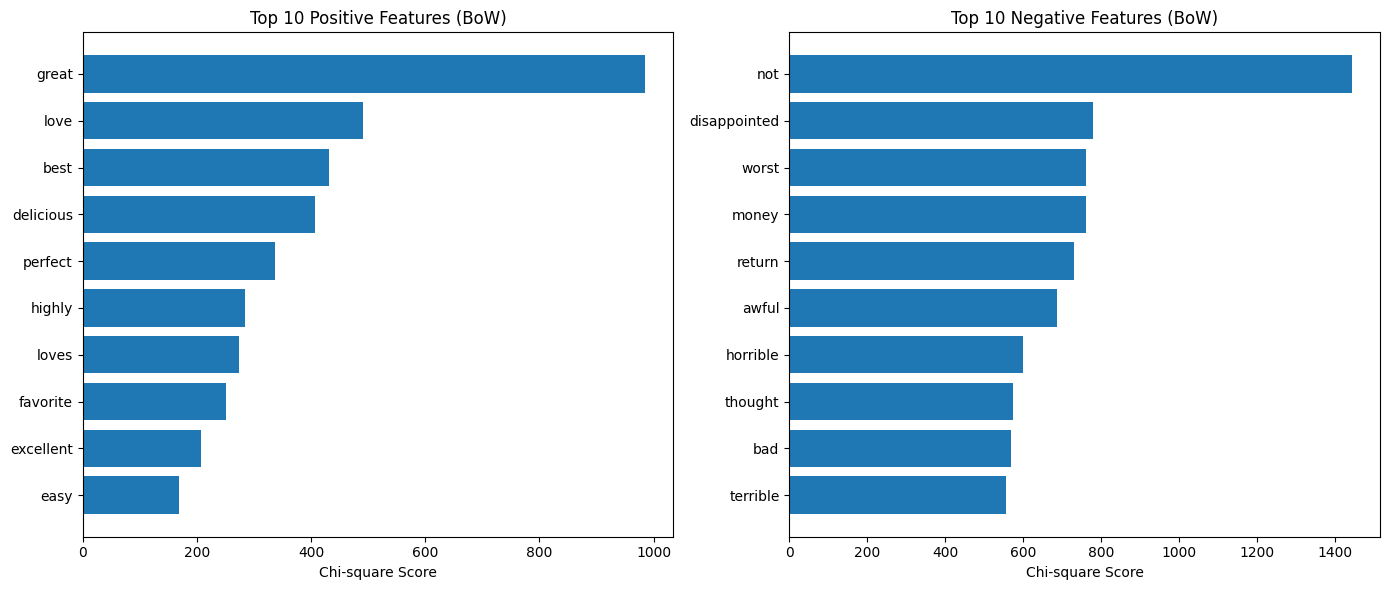

In [22]:
import matplotlib.pyplot as plt

# Get top features
positive_features = get_directional_features(
    X_train_bow,
    y_train,
    bow_vectorizer,
    "Positive",
    top_n=10
)

negative_features = get_directional_features(
    X_train_bow,
    y_train,
    bow_vectorizer,
    "Negative",
    top_n=10
)

# Create two side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Positive features
words = [x[0] for x in positive_features]
scores = [x[1] for x in positive_features]

axes[0].barh(words[::-1], scores[::-1])
axes[0].set_title("Top 10 Positive Features (BoW)")
axes[0].set_xlabel("Chi-square Score")

# Negative features
words = [x[0] for x in negative_features]
scores = [x[1] for x in negative_features]

axes[1].barh(words[::-1], scores[::-1])
axes[1].set_title("Top 10 Negative Features (BoW)")
axes[1].set_xlabel("Chi-square Score")

plt.tight_layout()

# Save visualization
plt.savefig("m2_bow_top_features.png", dpi=300, bbox_inches="tight")

plt.show()

In [23]:
from google.colab import files

files.download('/content/m2_bow_top_features.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>